In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report,
                             ConfusionMatrixDisplay)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
sample_sub = pd.read_csv("sample_submission.csv")

# Perbaiki salah ketik nama kolom pada file test
test = test.rename(columns={"seepal_width": "sepal_width"})

TARGET = "species"
ID_COL = "id"

print("Train :", train.shape)
print("Test  :", test.shape)
print("Sample:", sample_sub.shape)

Train : (105, 5)
Test  : (45, 5)
Sample: (45, 2)


In [2]:
display(train.head())
train.info()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,2.5,3.0,1.1,versicolor
1,6.2,2.2,4.5,1.5,versicolor
2,5.1,3.8,1.5,0.3,setosa
3,6.8,3.2,5.9,2.3,virginica
4,5.7,2.8,4.1,1.3,versicolor


<class 'pandas.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  105 non-null    float64
 1   sepal_width   105 non-null    float64
 2   petal_length  105 non-null    float64
 3   petal_width   105 non-null    float64
 4   species       105 non-null    str    
dtypes: float64(4), str(1)
memory usage: 4.2 KB


Total missing value: 0
Duplikat baris     : 1


,sepal_length,sepal_width,petal_length,petal_width,species
85,5.8,2.7,5.1,1.9,virginica
98,5.8,2.7,5.1,1.9,virginica


,count,mean,std,min,25%,50%,75%,max
sepal_length,105.0,5.87,0.86,4.3,5.1,5.8,6.4,7.9
sepal_width,105.0,3.06,0.46,2.0,2.8,3.0,3.3,4.4
petal_length,105.0,3.78,1.78,1.1,1.6,4.2,5.1,6.9
petal_width,105.0,1.21,0.78,0.1,0.3,1.3,1.9,2.5



Jumlah kelas: 3
species
versicolor    35
setosa        35
virginica     35
Name: count, dtype: int64


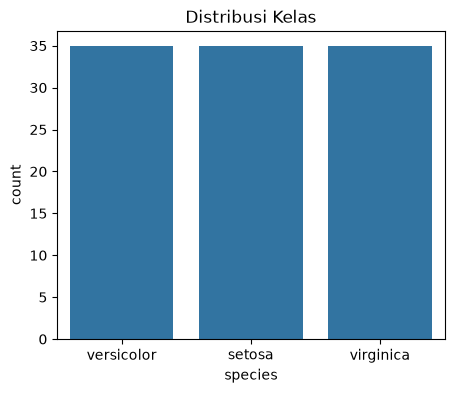

In [3]:
print("Total missing value:", train.isna().sum().sum())
print("Duplikat baris     :", train.duplicated().sum())
display(train[train.duplicated(keep=False)])

display(train.describe().T.round(2))

jumlah = train[TARGET].value_counts()
print("\nJumlah kelas:", train[TARGET].nunique())
print(jumlah)

plt.figure(figsize=(5, 4))
sns.countplot(x=TARGET, data=train, order=jumlah.index)
plt.title("Distribusi Kelas")
plt.show()

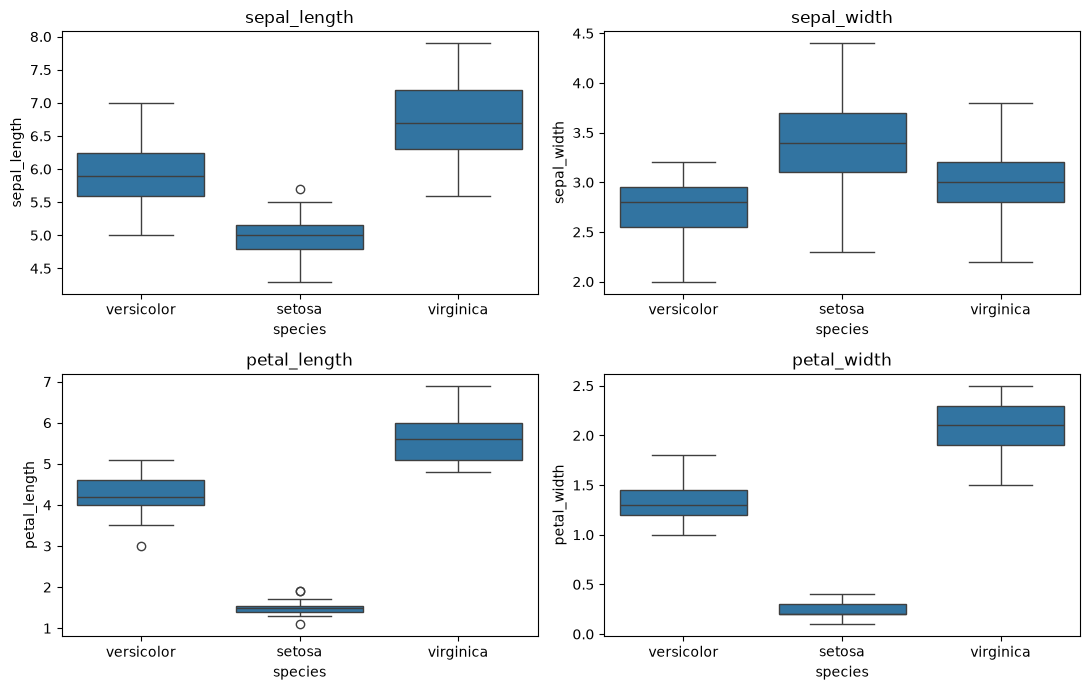

In [4]:
fitur = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

# Sebaran tiap fitur per spesies
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), fitur):
    sns.boxplot(x=TARGET, y=col, data=train, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

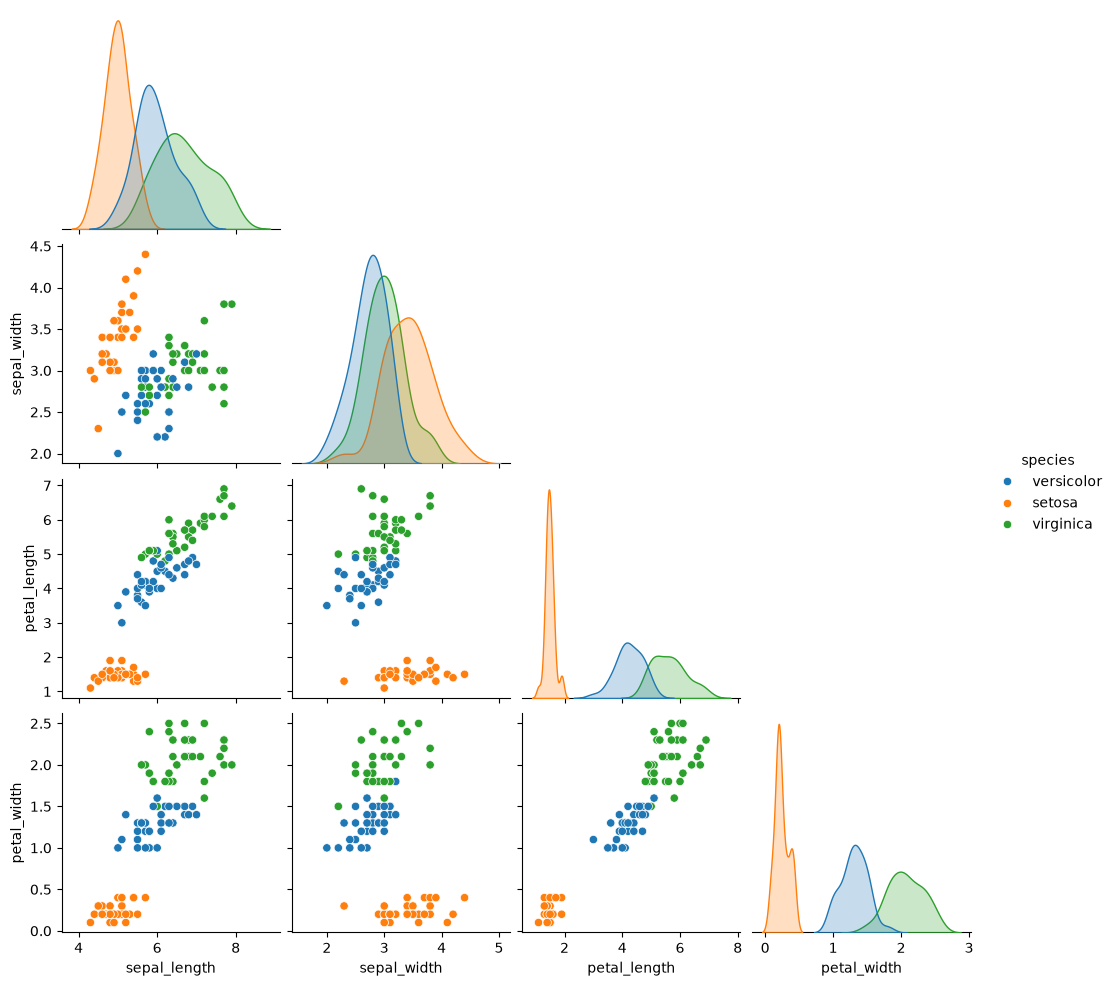

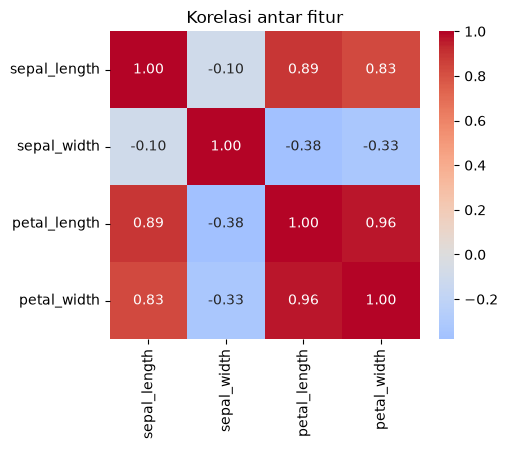

In [5]:
# Hubungan antar fitur
sns.pairplot(train, hue=TARGET, corner=True)
plt.show()

plt.figure(figsize=(5, 4))
sns.heatmap(train[fitur].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasi antar fitur")
plt.show()

In [6]:
X = train[fitur]
le = LabelEncoder()
y = pd.Series(le.fit_transform(train[TARGET]), index=train.index)
nama_kelas = list(le.classes_)

print("Pemetaan label:")
for i, k in enumerate(nama_kelas):
    print(f"  {i} -> {k}")

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("\nTrain:", X_train.shape, "| Validasi:", X_val.shape)

Pemetaan label:
  0 -> setosa
  1 -> versicolor
  2 -> virginica

Train: (84, 4) | Validasi: (21, 4)


In [7]:
models = {
    "Logistic Regression": Pipeline([("sc", StandardScaler()),
                                     ("clf", LogisticRegression(max_iter=2000))]),
    "KNN": Pipeline([("sc", StandardScaler()),
                     ("clf", KNeighborsClassifier(n_neighbors=5))]),
    "SVM": Pipeline([("sc", StandardScaler()),
                     ("clf", SVC(probability=True, random_state=42))]),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "roc_auc_ovr"]

rows = []
for nama, model in models.items():
    hasil = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"Model": nama, **{m: hasil[f"test_{m}"].mean() for m in scoring}})

hasil_cv = pd.DataFrame(rows).set_index("Model").round(4).sort_values("f1_macro", ascending=False)
display(hasil_cv)

,accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr
Model,,,,,
Logistic Regression,0.9647,0.9667,0.9667,0.9636,0.9936
KNN,0.9529,0.9571,0.9556,0.9524,0.9885
SVM,0.9529,0.9571,0.9556,0.9524,0.9958
Random Forest,0.9404,0.9476,0.9444,0.9392,0.9967
Gradient Boosting,0.9404,0.9476,0.9444,0.9392,0.9822
Decision Tree,0.9279,0.9343,0.9311,0.9269,0.9481


In [8]:
fitted, rows = {}, []
for nama, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    proba = model.predict_proba(X_val)
    fitted[nama] = model
    rows.append({
        "Model": nama,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision (macro)": precision_score(y_val, pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_val, pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_val, pred, average="macro", zero_division=0),
        "ROC-AUC (OvR)": roc_auc_score(y_val, proba, multi_class="ovr", average="macro"),
    })

hasil_val = pd.DataFrame(rows).set_index("Model").round(4).sort_values("F1 (macro)", ascending=False)
display(hasil_val)

,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC (OvR)
Model,,,,,
Logistic Regression,1.0,1.0,1.0,1.0,1.0
KNN,1.0,1.0,1.0,1.0,1.0
SVM,1.0,1.0,1.0,1.0,1.0
Decision Tree,1.0,1.0,1.0,1.0,1.0
Random Forest,1.0,1.0,1.0,1.0,1.0
Gradient Boosting,1.0,1.0,1.0,1.0,1.0


Model terbaik: Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00         7
  versicolor       1.00      1.00      1.00         7
   virginica       1.00      1.00      1.00         7

    accuracy                           1.00        21
   macro avg       1.00      1.00      1.00        21
weighted avg       1.00      1.00      1.00        21



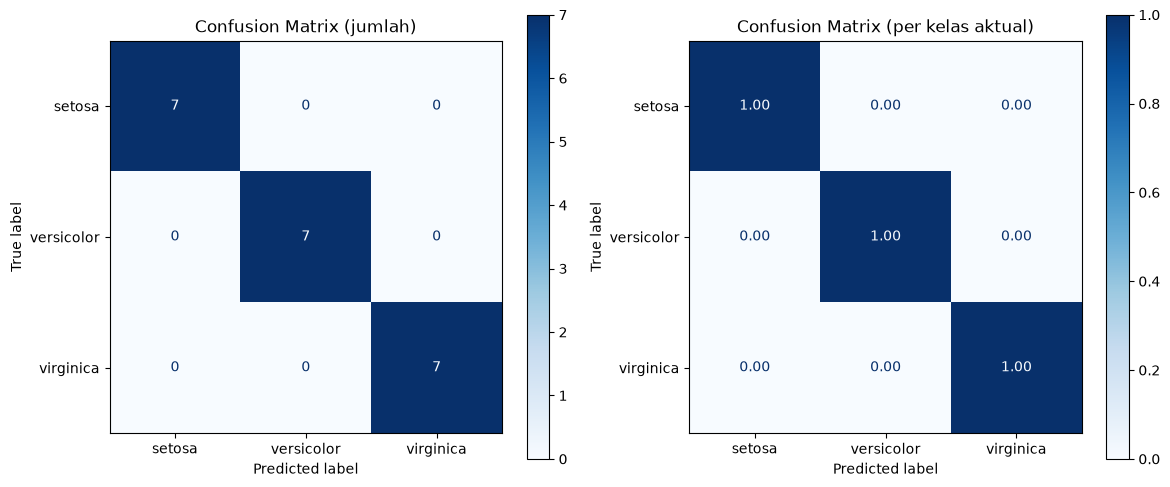

In [9]:
nama_terbaik = hasil_val.index[0]
terbaik = fitted[nama_terbaik]
pred = terbaik.predict(X_val)

print("Model terbaik:", nama_terbaik)
print(classification_report(y_val, pred, target_names=nama_kelas, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_val, pred, display_labels=nama_kelas,
                                        cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion Matrix (jumlah)")
ConfusionMatrixDisplay.from_predictions(y_val, pred, display_labels=nama_kelas,
                                        cmap="Blues", normalize="true",
                                        values_format=".2f", ax=axes[1])
axes[1].set_title("Confusion Matrix (per kelas aktual)")
plt.tight_layout()
plt.show()

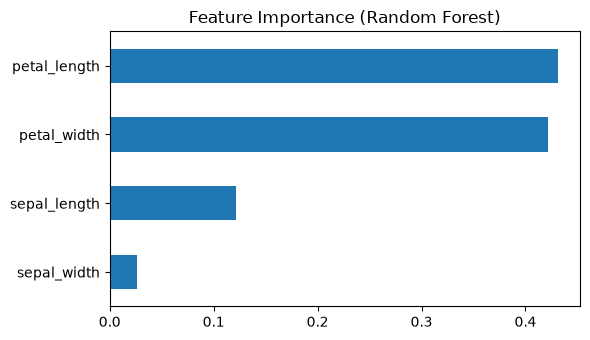

In [10]:
rf = fitted["Random Forest"]
penting = pd.Series(rf.feature_importances_, index=fitur).sort_values()

plt.figure(figsize=(6, 3.5))
penting.plot(kind="barh")
plt.title("Feature Importance (Random Forest)")
plt.tight_layout()
plt.show()

In [11]:
final_model = models[nama_terbaik]
final_model.fit(X, y)

X_test = test[fitur]                       # urutan kolom sama dengan train
pred_test = le.inverse_transform(final_model.predict(X_test))   # kembali ke label teks

submission = pd.DataFrame({ID_COL: test[ID_COL], TARGET: pred_test})
submission = sample_sub[[ID_COL]].merge(submission, on=ID_COL, how="left")   # samakan urutan

assert submission.shape == sample_sub.shape
assert submission[TARGET].notna().all()

submission.to_csv("submission_iris.csv", index=False)
display(submission.head())
print(submission[TARGET].value_counts())
print("Tersimpan: submission_iris.csv")

,id,species
0,0,virginica
1,1,versicolor
2,2,versicolor
3,3,versicolor
4,4,virginica


species
versicolor    17
setosa        15
virginica     13
Name: count, dtype: int64
Tersimpan: submission_iris.csv


# README: Dataset Iris (Klasifikasi Multikelas)

## Ringkasan dataset

| Item | Keterangan |
|---|---|
| File | `train_1.csv`, `test_1.csv`, `sample_submission_69b9b4.csv` |
| Jumlah data | Train 105 baris, test 45 baris |
| Kolom train | 5 kolom: 4 fitur numerik dan 1 target (`species`) |
| Fitur | `sepal_length`, `sepal_width`, `petal_length`, `petal_width` |
| Target | `species` |
| Missing value | Tidak ada |
| Duplikat | 1 baris di train (sesama virginica dengan nilai identik) |

Dataset ini berisi ukuran bagian bunga (kelopak dan mahkota) beserta spesiesnya.

## Mengapa ini termasuk klasifikasi multikelas

1. **Pembelajaran terawasi (supervised).** Setiap baris pada data train sudah punya label `species`.
2. **Targetnya kategorikal, bukan angka kontinu.** `species` adalah nama spesies bunga, bukan besaran yang diukur. Karena itu masalahnya bukan regresi.
3. **Targetnya punya lebih dari dua kelas.** Ada tepat 3 kelas, sehingga bukan klasifikasi biner.

| Kelas `species` | Jumlah (train) | Persentase |
|---|---|---|
| setosa | 35 | 33,3% |
| versicolor | 35 | 33,3% |
| virginica | 35 | 33,3% |

4. **Setiap data hanya punya satu kelas (single-label).** Satu bunga hanya masuk ke satu spesies. Inilah pembeda dari klasifikasi multi-label, tempat satu data boleh punya beberapa label sekaligus.
5. **Keluaran model berupa satu pilihan dari tiga kelas.** Format `sample_submission_69b9b4.csv` meminta satu nama spesies untuk setiap `id`.

## Karakteristik penting

- **Kelas seimbang sempurna** (35:35:35), sehingga accuracy cukup layak dipakai. Meski begitu, tetap laporkan F1 macro dan lihat hasil per kelas.
- **Pengkodean label:** nama spesies diubah menjadi angka 0, 1, 2 dengan `LabelEncoder`. Angka ini hanya kode, bukan urutan atau besaran. Hasil prediksi dikembalikan ke nama spesies sebelum disimpan ke submission.
- **Salah ketik pada file test:** kolom `sepal_width` tertulis `seepal_width`. Nama kolom diperbaiki di kode supaya cocok dengan data train.
- **Kolom `id`** hanya ada di file test dan dipakai untuk mencocokkan submission, bukan sebagai fitur.
- **Fitur paling informatif:** `petal_length` dan `petal_width`. `sepal_width` paling lemah.
- **Data kecil.** Selisih antar model sangat tipis dan bisa berubah jika cara pembagian datanya diganti.

## Hasil baseline (5-fold cross-validation pada data train)

| Model | Accuracy | F1 macro | ROC-AUC (OvR) |
|---|---|---|---|
| Logistic Regression | 0,981 | 0,981 | 0,993 |
| SVM | 0,971 | 0,971 | 0,995 |
| Random Forest | 0,952 | 0,952 | 0,999 |
| Gradient Boosting | 0,943 | 0,943 | 0,995 |
| KNN | 0,933 | 0,933 | 0,995 |
| Decision Tree | 0,933 | 0,933 | 0,950 |

Pada klasifikasi multikelas, metrik precision, recall, dan F1 dihitung per kelas lalu dirata-ratakan (macro). ROC-AUC memakai skema One-vs-Rest (OvR), yaitu tiap kelas dibandingkan dengan gabungan kelas lainnya.